In [1]:
import json, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
import tensorflow as tf
from tensorflow.keras import layers, models, callbacks
from sklearn.metrics import f1_score, accuracy_score
from sklearn.neighbors import NearestNeighbors

SEED = 42; ART = Path("artifacts")
CLASS_NAMES = json.load(open(ART/"class_names.json")); K = len(CLASS_NAMES)
ST_COLS = json.load(open(ART/"st_cols.json"))
ftr = pd.read_pickle(ART/"ftr.pkl"); SEQ = np.load(ART/"SEQ.npy")
ST = np.nan_to_num(ftr[ST_COLS].values.astype(np.float32))
y = ftr.label.values.astype(int); fold = ftr.fold.values; N = len(y)
T, NCH, NST = SEQ.shape[1], SEQ.shape[2], ST.shape[1]

def soft_weights(y_, power=0.5):
    cnt = np.bincount(y_, minlength=K).astype(float); cnt[cnt == 0] = 1
    cw = (cnt.sum() / (K * cnt)) ** power
    return cw / cw[y_].mean()

def build_ann():
    seq = layers.Input((T, NCH), name="seq"); st = layers.Input((NST,), name="st")
    x = layers.Concatenate()([layers.Flatten()(seq), st])
    for u, d in ((256, .3), (128, .3), (64, .2)):
        x = layers.Dense(u, activation="relu")(x); x = layers.BatchNormalization()(x); x = layers.Dropout(d)(x)
    m = models.Model({"seq": seq, "st": st}, layers.Dense(K, activation="softmax")(x))
    m.compile(optimizer=tf.keras.optimizers.Adam(1e-3, clipnorm=1.0), loss="sparse_categorical_crossentropy")
    return m

EMB = np.zeros((5, N, 64), np.float32)       # EMB[k] = every field embedded by the fold-k model
P_OOF = np.zeros((N, K), np.float32)
for k in range(5):
    tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
    tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEED)
    rng = np.random.RandomState(SEED)
    inner = rng.choice(tr, size=int(0.1*len(tr)), replace=False); fit = np.setdiff1d(tr, inner)
    smu, ssd = SEQ[fit].mean((0,1), keepdims=True), SEQ[fit].std((0,1), keepdims=True) + 1e-6
    tmu, tsd = ST[fit].mean(0, keepdims=True), ST[fit].std(0, keepdims=True) + 1e-6
    X = lambda ids: {"seq": ((SEQ[ids]-smu)/ssd).astype(np.float32),
                     "st": np.nan_to_num((ST[ids]-tmu)/tsd).astype(np.float32)}
    cw = soft_weights(y[fit]); model = build_ann()
    cb = [callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
          callbacks.ReduceLROnPlateau(factor=0.5, patience=4)]
    model.fit(X(fit), y[fit], sample_weight=cw[y[fit]].astype(np.float32),
              validation_data=(X(inner), y[inner], cw[y[inner]].astype(np.float32)),
              epochs=80, batch_size=128, callbacks=cb, verbose=0)
    P_OOF[va] = model.predict(X(va), batch_size=512, verbose=0)
    enc = models.Model(model.input, model.layers[-2].output)       # 64-d embedding
    EMB[k] = enc.predict(X(np.arange(N)), batch_size=512, verbose=0)
    model.save(ART/f"ann_fold{k}.keras")
    np.savez(ART/f"scaler_fold{k}.npz", smu=smu, ssd=ssd, tmu=tmu, tsd=tsd)
    print(f"fold {k}: macroF1={f1_score(y[va], P_OOF[va].argmax(1), average='macro'):.3f}")

print("ANN OOF  acc", accuracy_score(y, P_OOF.argmax(1)).round(4),
      "| macroF1", f1_score(y, P_OOF.argmax(1), average="macro").round(4))   # expect ~0.39
np.save(ART/"emb_by_fold.npy", EMB); np.save(ART/"ann_oof_probs.npy", P_OOF)

# Agent-2 preview: leak-free kNN retrieval, cosine, k=15
pred = np.zeros((N, K))
for k in range(5):
    tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
    nn = NearestNeighbors(n_neighbors=15, metric="cosine").fit(EMB[k][tr])
    _, idx = nn.kneighbors(EMB[k][va])
    for r, row in enumerate(idx):
        pred[va[r]] = np.bincount(y[tr][row], minlength=K) / 15
print("kNN-retrieval macroF1:", f1_score(y, pred.argmax(1), average="macro").round(4))

# sanity plot for Agent 3 rules: mean NDVI curve per class (channel 4 = NDVI)
for c in ["Rice", "Fallow", "Potato", "Mustard", "Sugarcane", "Wheat"]:
    plt.plot(np.arange(0, 243, 10), SEQ[y == CLASS_NAMES.index(c), :, 4].mean(0), label=c)
plt.legend(); plt.xlabel("days since 1 Oct 2021"); plt.ylabel("mean NDVI"); plt.show()

2026-11-05 17:48:43.139580: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-11-05 17:48:43.165700: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16, in other operations, rebuild TensorFlow with the appropriate compiler flags.


fold 0: macroF1=0.345
fold 1: macroF1=0.448
fold 2: macroF1=0.370
fold 3: macroF1=0.382
fold 4: macroF1=0.423


AttributeError: 'float' object has no attribute 'round'

ANN OOF  acc 0.7067 | macroF1 0.3916
kNN-retrieval acc 0.7235 | macroF1 0.3716


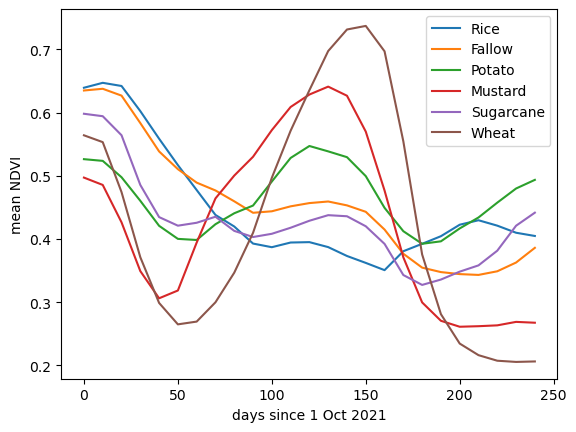

In [2]:
print("ANN OOF  acc", round(accuracy_score(y, P_OOF.argmax(1)), 4),
      "| macroF1", round(f1_score(y, P_OOF.argmax(1), average="macro"), 4))   # expect ~0.39
np.save(ART/"emb_by_fold.npy", EMB); np.save(ART/"ann_oof_probs.npy", P_OOF)

# Agent-2 preview: leak-free kNN retrieval, cosine, k=15
pred = np.zeros((N, K))
for k in range(5):
    tr, va = np.where(fold != k)[0], np.where(fold == k)[0]
    nn = NearestNeighbors(n_neighbors=15, metric="cosine").fit(EMB[k][tr])
    _, idx = nn.kneighbors(EMB[k][va])
    for r, row in enumerate(idx):
        pred[va[r]] = np.bincount(y[tr][row], minlength=K) / 15
np.save(ART/"knn_oof_probs.npy", pred)
print("kNN-retrieval acc", round(accuracy_score(y, pred.argmax(1)), 4),
      "| macroF1", round(f1_score(y, pred.argmax(1), average="macro"), 4))

# sanity plot for Agent 3 rules: mean NDVI curve per class (channel 4 = NDVI)
for c in ["Rice", "Fallow", "Potato", "Mustard", "Sugarcane", "Wheat"]:
    plt.plot(np.arange(0, 243, 10), SEQ[y == CLASS_NAMES.index(c), :, 4].mean(0), label=c)
plt.legend(); plt.xlabel("days since 1 Oct 2021"); plt.ylabel("mean NDVI"); plt.show()